<a href="https://colab.research.google.com/github/akshaya19200/Akshaya_Customer_Analysis/blob/main/LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

file_path = "/content/household_power/household_power_consumption.txt"

if not os.path.exists(file_path):
    from google.colab import files
    uploaded = files.upload()
    txt_files = [f for f in uploaded if f.endswith(".txt")]
    if not txt_files:
        raise FileNotFoundError("Upload the household power .txt dataset.")
    file_path = "/content/" + txt_files[0]

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully")
print("Original rows and columns:", df.shape)
display(df.head())

Saving household_power_consumption.txt to household_power_consumption.txt
Dataset loaded successfully
Original rows and columns: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [2]:
FEATURES = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df["Timestamp"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

data = df[["Timestamp"] + FEATURES].dropna(
    subset=["Timestamp"]
)
data = data.sort_values("Timestamp")
data = data.drop_duplicates("Timestamp")
data = data.set_index("Timestamp")

# Include any missing minutes in the timeline.
full_minutes = pd.date_range(
    data.index.min(),
    data.index.max(),
    freq="min"
)
data = data.reindex(full_minutes)
data.index.name = "Timestamp"

# Fill missing measurements.
data[FEATURES] = data[FEATURES].interpolate(
    method="time",
    limit_direction="both"
)
data[FEATURES] = data[FEATURES].ffill().bfill()
data = data.reset_index()

if data[FEATURES].isna().any().any():
    raise ValueError("Missing values remain. Check the dataset.")

if not np.isfinite(data[FEATURES].to_numpy()).all():
    raise ValueError("Dataset contains infinite values.")

print("Cleaned records:", len(data))
print("Remaining missing values:", int(data[FEATURES].isna().sum().sum()))
print("Start timestamp:", data["Timestamp"].min())
print("End timestamp:", data["Timestamp"].max())

Cleaned records: 2075259
Remaining missing values: 0
Start timestamp: 2006-12-16 17:24:00
End timestamp: 2010-11-26 21:02:00


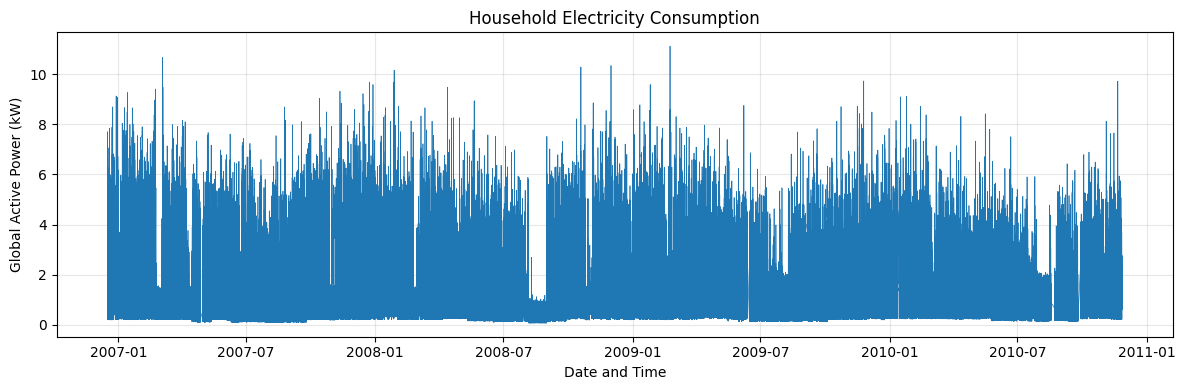

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(data["Timestamp"], data["Global_active_power"], linewidth=0.5)
plt.title("Household Electricity Consumption")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
WINDOW_SIZE = 60
TARGET = "Global_active_power"
TARGET_INDEX = FEATURES.index(TARGET)

values = data[FEATURES].to_numpy(dtype=np.float32)
n = len(values)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scaler on training data only.
scaler = MinMaxScaler()
scaler.fit(values[:train_end])

scaled = scaler.transform(values).astype(np.float32)

print("Total records:", n)
print("Training period:", train_end, "rows")
print("Validation period:", val_end - train_end, "rows")
print("Test period:", n - val_end, "rows")
print("Features:", len(FEATURES))

Total records: 2075259
Training period: 1452681 rows
Validation period: 311289 rows
Test period: 311289 rows
Features: 7


In [5]:
BATCH_SIZE = 128
WINDOW_STRIDE = 5

def make_dataset(first_target, end_target, stride=WINDOW_STRIDE):
    # Target positions are [first_target, end_target).
    x_data = scaled[first_target - WINDOW_SIZE:end_target - 1]
    y_data = scaled[first_target:end_target, TARGET_INDEX]

    return tf.keras.utils.timeseries_dataset_from_array(
        data=x_data,
        targets=y_data,
        sequence_length=WINDOW_SIZE,
        sequence_stride=stride,
        shuffle=False,
        batch_size=BATCH_SIZE
    )

train_ds = make_dataset(WINDOW_SIZE, train_end)
val_ds = make_dataset(train_end, val_end)
test_ds = make_dataset(val_end, n)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 2270
Validation batches: 487
Test batches: 487


In [6]:
model = Sequential([
    Input(shape=(WINDOW_SIZE, len(FEATURES))),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

# Report MAE in the original kW scale during training.
target_range = float(
    scaler.data_max_[TARGET_INDEX] - scaler.data_min_[TARGET_INDEX]
)
target_range_tf = tf.constant(target_range, dtype=tf.float32)

def mae_kw(y_true, y_pred):
    return tf.reduce_mean(
        tf.abs(y_true - y_pred) * target_range_tf
    )

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=[mae_kw]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,153 (20.13 KB)

 Trainable params: 5,153 (20.13 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop],
    verbose=1
)

print("\nTraining finished.")
print("Epochs completed:", len(history.history["loss"]))

Epoch 1/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 84s 36ms/step - loss: 0.0014 - mae_kw: 0.8580 - val_loss: 5.2188e-04 - val_mae_kw: 0.8788
Epoch 2/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 80s 35ms/step - loss: 7.1711e-04 - mae_kw: 0.8497 - val_loss: 4.6971e-04 - val_mae_kw: 0.8797
Epoch 3/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 81s 36ms/step - loss: 6.7036e-04 - mae_kw: 0.8509 - val_loss: 4.5883e-04 - val_mae_kw: 0.8817
Epoch 4/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 78s 34ms/step - loss: 6.5268e-04 - mae_kw: 0.8511 - val_loss: 4.5746e-04 - val_mae_kw: 0.8896
Epoch 5/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 78s 34ms/step - loss: 6.4712e-04 - mae_kw: 0.8513 - val_loss: 4.5102e-04 - val_mae_kw: 0.8794
Epoch 6/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 76s 33ms/step - loss: 6.3797e-04 - mae_kw: 0.8510 - val_loss: 4.5053e-04 - val_mae_kw: 0.8882
Epoch 7/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 76s 33ms/step - loss: 6.2804e-04 - mae_kw: 0.8509 - val_loss: 4.4952e-04 - val_mae_kw: 0.8835
Epoch 8/15
2270/2270 ━━━━━━━━━━━━━━━━━━━━ 77s 34ms/s

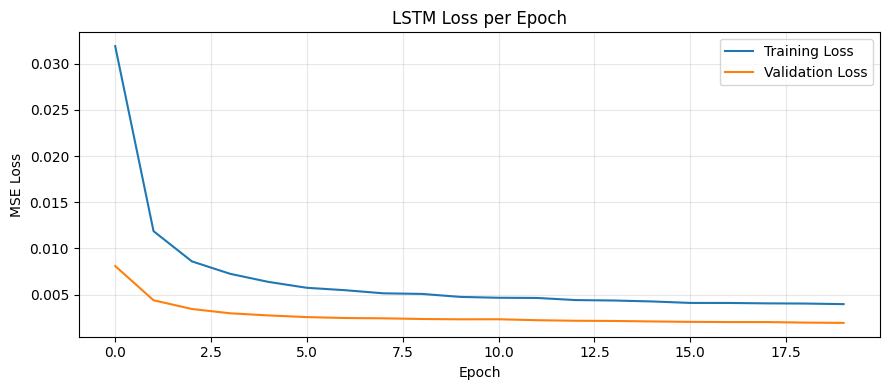

In [15]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
actual_scaled = []
predicted_scaled = []

for batch_x, batch_y in test_ds:
    batch_pred = model.predict(batch_x, verbose=0).reshape(-1)
    actual_scaled.extend(batch_y.numpy().reshape(-1))
    predicted_scaled.extend(batch_pred)

actual_scaled = np.asarray(actual_scaled)
predicted_scaled = np.asarray(predicted_scaled)

# Convert normalized values back to kW.
target_min = scaler.data_min_[TARGET_INDEX]

actual_kw = actual_scaled * target_range + target_min
predicted_kw = predicted_scaled * target_range + target_min

# Keep raw model predictions for honest evaluation.
mae = mean_absolute_error(actual_kw, predicted_kw)
rmse = np.sqrt(mean_squared_error(actual_kw, predicted_kw))

print(f"Test MAE:  {mae:.4f} kW")
print(f"Test RMSE: {rmse:.4f} kW")
print(f"Test predictions evaluated: {len(actual_kw)}")

Test MAE:  0.1237 kW
Test RMSE: 0.2547 kW
Test predictions evaluated: 62258


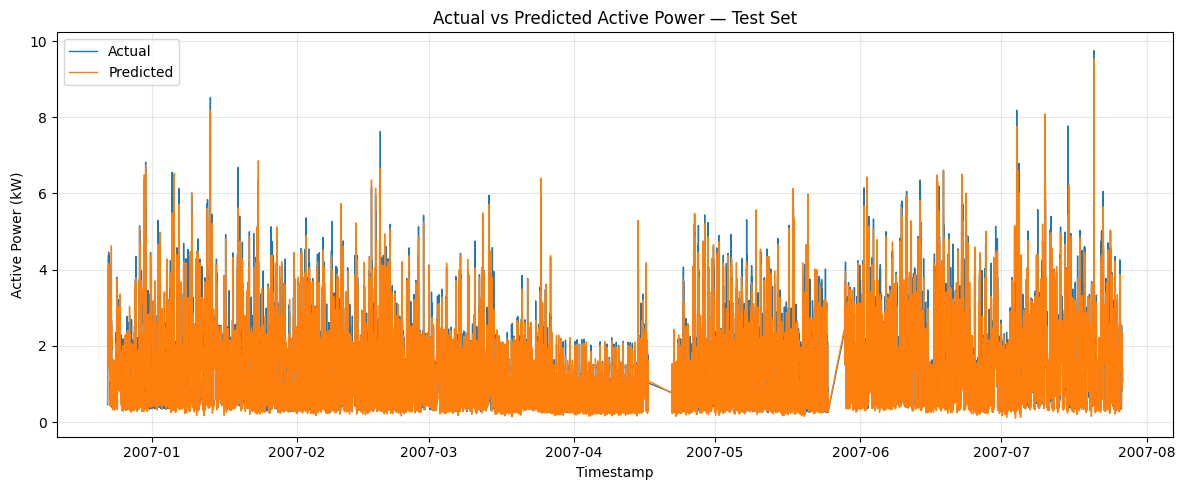

In [17]:
test_positions = val_end + np.arange(len(actual_kw)) * WINDOW_STRIDE
test_positions = test_positions[:len(actual_kw)]

plt.figure(figsize=(12, 5))
plt.plot(
    data["Timestamp"].iloc[test_positions],
    actual_kw,
    label="Actual",
    linewidth=1
)
plt.plot(
    data["Timestamp"].iloc[test_positions],
    predicted_kw,
    label="Predicted",
    linewidth=1
)
plt.title("Actual vs Predicted Active Power — Test Set")
plt.xlabel("Timestamp")
plt.ylabel("Active Power (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
latest_60 = data[FEATURES].tail(WINDOW_SIZE).to_numpy(
    dtype=np.float32
)

latest_60_scaled = scaler.transform(latest_60)

next_scaled = model.predict(
    latest_60_scaled.reshape(1, WINDOW_SIZE, len(FEATURES)),
    verbose=0
)[0, 0]

next_kw_raw = float(next_scaled * target_range + target_min)

# Physical constraint for active power.
next_kw = max(0.0, next_kw_raw)

print("Latest recorded active power:",
      f'{data[TARGET].iloc[-1]:.4f} kW')
print("Predicted next-minute active power:",
      f"{next_kw:.4f} kW")

Latest recorded active power: 0.9320 kW
Predicted next-minute active power: 1.2945 kW


In [19]:
PRODUCT_DIR = "/content/smartpower_product"
os.makedirs(PRODUCT_DIR, exist_ok=True)

# Save the trained model and preprocessing scaler.
model.save(os.path.join(PRODUCT_DIR, "electricity.keras"))
joblib.dump(scaler, os.path.join(PRODUCT_DIR, "scalar.pkl"))

config = {
    "features": FEATURES,
    "target": TARGET,
    "window_size": WINDOW_SIZE,
    "target_index": TARGET_INDEX,
    "mae_kw": float(mae),
    "rmse_kw": float(rmse)
}

with open(os.path.join(PRODUCT_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=4)

# Save 60 real dataset readings to test in the web application.
data[["Timestamp"] + FEATURES].tail(WINDOW_SIZE).to_csv(
    os.path.join(PRODUCT_DIR, "sample_input.csv"),
    index=False
)

# Save actual and predicted test results.
test_results = pd.DataFrame({
    "Timestamp": data["Timestamp"].iloc[test_positions].to_numpy(),
    "Actual_kW": actual_kw,
    "Predicted_kW": predicted_kw
})

test_results.to_csv(
    os.path.join(PRODUCT_DIR, "test_predictions.csv"),
    index=False
)

print("Saved files:")
print(os.listdir(PRODUCT_DIR))
print(f"Final Test MAE: {mae:.4f} kW")
print(f"Final Test RMSE: {rmse:.4f} kW")

Saved files:
['config.json', 'sample_input.csv', 'scalar.pkl', 'test_predictions.csv', 'electricity.keras']
Final Test MAE: 0.1237 kW
Final Test RMSE: 0.2547 kW
